# Is a compound toxic when DILI, caspase-3/7 and MMP are all active?

Three binary labels per compound, giving a 3-bit pattern `DILI-caspase-MMP`, and the
question of whether `1-1-1` concentrates hepatotoxicity.

All three labels here are **measured**, not predicted:

| Label | Source |
|---|---|
| DILI | `TOXICITY` from the DILI universe (Alloriginal / NCV-888 / Held-223) |
| MMP | PubChem AID 720637 activity outcome, HepG2 |
| Caspase-3/7 | PubChem AID 654 + 1347034 activity outcome, HepG2 |

The two assay label vectors are read from `data_mmp/` and `data_caspase/`, which
`prepare_assay_oob.py` already built: `PUBCHEM_ACTIVITY_OUTCOME` mapped to
Active=1 / Inactive=0, deduplicated by InChIKey with majority vote on conflicts.
Reusing them rather than re-deriving guarantees these are the same labels the
assay models were trained against.

Run order is one step at a time, each step checked against a number already in the
paper before the next is added.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

LINK = os.path.abspath('..')          # DILI_assay_link/
RES = 'results'                       # triple_pattern/results/
os.makedirs(RES, exist_ok=True)

pd.set_option('display.width', 120)

## Step 1 - the two HepG2 assays, and their overlap

How many compounds were tested in **both** the MMP and the caspase-3/7 summary
assays. The paper's Table `tab:caspase_mito` reports 4,879 tested in both.

In [2]:
def load_assay(name):
    ikeys = [l.strip() for l in open(f'{LINK}/data_{name}/ikeys_all.txt')]
    y = np.load(f'{LINK}/data_{name}/y_all.npy')
    print(f'{name:8s}: {len(ikeys):5d} compounds, {int(y.sum()):4d} active '
          f'({y.mean():.1%})')
    return pd.DataFrame({'InChIKey': ikeys, name: y})

mmp = load_assay('mmp')
caspase = load_assay('caspase')

both = mmp.merge(caspase, on='InChIKey', how='inner')
print(f'\ntested in both : {len(both)} compounds')

mmp     :  5937 compounds,  857 active (14.4%)
caspase :  7282 compounds,  281 active (3.9%)

tested in both : 4878 compounds


## Step 2 - the 2x2, before DILI is added

Cross-tabulating the two measured assay labels should reproduce the paper's
106 / 20 / 511 / 4,242 table. Any mismatch here means the notebook is reading
different data from the paper, and nothing downstream would be trustworthy.

In [3]:
ct = pd.crosstab(both.caspase, both.mmp,
                 rownames=['caspase'], colnames=['mmp'])
print(ct, '\n')

paper = {'both active': 106, 'caspase only': 20, 'mmp only': 511,
         'both inactive': 4242}
ours = {'both active': int(ct.loc[1, 1]), 'caspase only': int(ct.loc[1, 0]),
        'mmp only': int(ct.loc[0, 1]), 'both inactive': int(ct.loc[0, 0])}
chk = pd.DataFrame({'paper': paper, 'this notebook': ours})
chk['diff'] = chk['this notebook'] - chk['paper']
print(chk)

mmp         0    1
caspase           
0        4242  511
1          20  105 

               paper  this notebook  diff
both active      106            105    -1
caspase only      20             20     0
mmp only         511            511     0
both inactive   4242           4242     0


## Step 2b - the four caspase/MMP combinations on their own

Dropping the DILI axis uses **all 4,878** compounds tested in both assays, not just
the 3,853 that also carry a DILI label, and it is free of any DILI-labelling
question. This is the in vitro picture by itself.

caspase-MMP 0-0 (neither active):  4242  (86.96%)
caspase-MMP 0-1 (MMP only      ):   511  (10.48%)
caspase-MMP 1-0 (caspase only  ):    20  ( 0.41%)
caspase-MMP 1-1 (both active   ):   105  ( 2.15%)


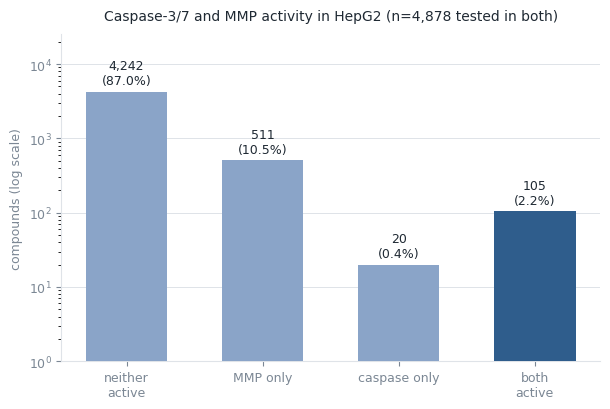

In [4]:
INK, MUTED, GRID = '#1f2933', '#7b8794', '#dfe3e8'
BAR, BAR_HI = '#8aa4c8', '#2f5d8c'

LBL2 = {'0-0': 'neither\nactive', '0-1': 'MMP only',
        '1-0': 'caspase only', '1-1': 'both\nactive'}
key = both.caspase.astype(str) + '-' + both.mmp.astype(str)
four = key.value_counts().reindex(['0-0', '0-1', '1-0', '1-1'])

for k, v in four.items():
    print(f'caspase-MMP {k} ({LBL2[k].replace(chr(10), " "):14s}): '
          f'{v:5d}  ({v / len(both):6.2%})')
four.rename('count').to_frame().to_csv(f'{RES}/caspase_mmp_counts.csv')

fig, ax = plt.subplots(figsize=(6.2, 4.2))
colors = [BAR_HI if k == '1-1' else BAR for k in four.index]
ax.bar([LBL2[k] for k in four.index], four.values, color=colors,
       width=0.6, zorder=3)
for x, v in enumerate(four.values):
    ax.text(x, v * 1.15, f'{v:,}\n({v / len(both):.1%})', ha='center',
            va='bottom', fontsize=9, color=INK)
ax.set_yscale('log')
ax.set_ylim(1, four.max() * 6)
ax.set_ylabel('compounds (log scale)', fontsize=9, color=MUTED)
ax.set_title(f'Caspase-3/7 and MMP activity in HepG2 (n={len(both):,} tested '
             f'in both)', fontsize=10, color=INK, pad=10)
ax.tick_params(colors=MUTED, labelsize=9)
ax.grid(axis='y', color=GRID, lw=0.7, zorder=0)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
for s in ('left', 'bottom'):
    ax.spines[s].set_color(GRID)
fig.tight_layout()
fig.savefig(f'{RES}/caspase_mmp_histogram.png', dpi=200, bbox_inches='tight')
plt.show()

## Step 3 - add the DILI label

Intersect the both-tested set with the DILI universe. This is the gate for the
whole analysis: a compound only enters the 3-bit table if it carries **all three**
measured labels, so the coverage per DILI set decides where the question can
actually be answered.

In [5]:
iv = pd.read_csv(f'{LINK}/results/invitro_features.csv',
                 usecols=['InChIKey', 'TOXICITY', 'dili_set'])

tri = both.merge(iv, on='InChIKey', how='inner').rename(
    columns={'TOXICITY': 'dili'})
print(f'compounds with all three measured labels: {len(tri)}\n')

cov = tri.groupby('dili_set').agg(
    n=('dili', 'size'), dili_pos=('dili', 'sum'),
    caspase_active=('caspase', 'sum'), mmp_active=('mmp', 'sum'))
cov['dili_rate'] = (cov.dili_pos / cov.n).round(3)
print(cov)

compounds with all three measured labels: 3853

                n  dili_pos  caspase_active  mmp_active  dili_rate
dili_set                                                          
Alloriginal  3656       924              68         458      0.253
Held-223       57        44               3           6      0.772
NCV-888       140        88               0          13      0.629


## Step 4 - the eight combinations

The 3-bit pattern is written `DILI-caspase-MMP`. Counts are reported for the full
three-way set and for Held-223 on its own.

In [6]:
def patterns(df):
    # counts of all 8 DILI-caspase-MMP patterns, missing ones as zero
    key = (df.dili.astype(str) + '-' + df.caspase.astype(str)
           + '-' + df.mmp.astype(str))
    idx = [f'{d}-{c}-{m}' for d in (0, 1) for c in (0, 1) for m in (0, 1)]
    out = key.value_counts().reindex(idx, fill_value=0).rename('count')
    out.index.name = 'DILI-caspase-MMP'
    return out.to_frame()

held = tri[tri.dili_set == 'Held-223']

pat_all = patterns(tri)
pat_held = patterns(held)
table = pat_all.join(pat_held, rsuffix='_held223')
table.columns = [f'all (n={len(tri)})', f'Held-223 (n={len(held)})']
table['% of all'] = (100 * table.iloc[:, 0] / len(tri)).round(2)
print(table)
table.to_csv(f'{RES}/pattern_counts.csv')

                  all (n=3853)  Held-223 (n=57)  % of all
DILI-caspase-MMP                                         
0-0-0                     2670               11     69.30
0-0-1                      100                0      2.60
0-1-0                       10                1      0.26
0-1-1                       17                1      0.44
1-0-0                      692               39     17.96
1-0-1                      320                4      8.31
1-1-0                        4                0      0.10
1-1-1                       40                1      1.04


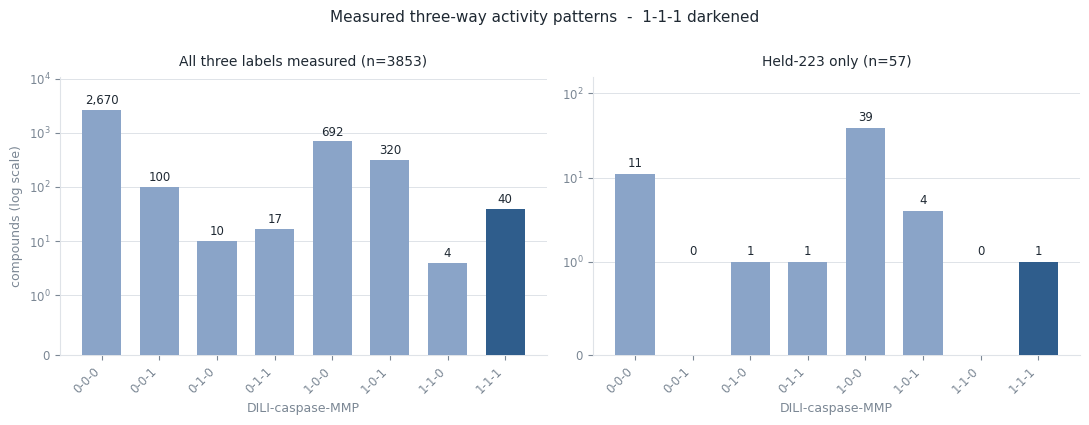

In [7]:
INK, MUTED, GRID = '#1f2933', '#7b8794', '#dfe3e8'
BAR, BAR_HI = '#8aa4c8', '#2f5d8c'      # one hue; the 1-1-1 bar darkened

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

for ax, counts, title in [
        (axes[0], pat_all['count'], f'All three labels measured (n={len(tri)})'),
        (axes[1], pat_held['count'], f'Held-223 only (n={len(held)})')]:
    colors = [BAR_HI if i == '1-1-1' else BAR for i in counts.index]
    ax.bar(counts.index, counts.values, color=colors, width=0.68, zorder=3)
    for x, v in enumerate(counts.values):
        ax.text(x, v * 1.12 if v else 1.12, f'{v:,}', ha='center', va='bottom',
                fontsize=8.5, color=INK)
    ax.set_yscale('symlog', linthresh=1)
    ax.set_ylim(0, counts.max() * 4 if counts.max() else 10)
    ax.set_title(title, fontsize=10, color=INK, pad=8)
    ax.set_xlabel('DILI-caspase-MMP', fontsize=9, color=MUTED)
    ax.tick_params(colors=MUTED, labelsize=8.5)
    ax.set_xticks(range(8))
    ax.set_xticklabels(counts.index, rotation=45, ha='right')
    ax.grid(axis='y', color=GRID, lw=0.7, zorder=0)
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)
    for s in ('left', 'bottom'):
        ax.spines[s].set_color(GRID)

axes[0].set_ylabel('compounds (log scale)', fontsize=9, color=MUTED)
fig.suptitle('Measured three-way activity patterns  -  1-1-1 darkened',
             fontsize=11, color=INK, y=1.0)
fig.tight_layout()
fig.savefig(f'{RES}/pattern_histogram.png', dpi=200, bbox_inches='tight')
plt.show()

## Step 5 - does all-ones mean toxic?

The histogram above counts patterns, which mixes two things together: how common an
in vitro pattern is, and how toxic it is. The claim under test is conditional, so it
needs the DILI-positive **rate within each in vitro cell**, against that population's
base rate.

In [8]:
def cell_rates(df, label):
    g = df.groupby(['caspase', 'mmp']).agg(
        n=('dili', 'size'), dili_pos=('dili', 'sum'))
    g['dili_rate'] = (g.dili_pos / g.n).round(3)
    g['lift_vs_base'] = (g.dili_rate / df.dili.mean()).round(2)
    print(f'=== {label}   n={len(df)}   base DILI+ rate={df.dili.mean():.3f}')
    print(g, '\n')
    return g

allo = tri[tri.dili_set == 'Alloriginal']
r_all = cell_rates(tri, 'all three-way compounds')
r_allo = cell_rates(allo, 'Alloriginal only')
r_held = cell_rates(held, 'Held-223 only')
r_all.to_csv(f'{RES}/dili_rate_by_cell.csv')

=== all three-way compounds   n=3853   base DILI+ rate=0.274
                n  dili_pos  dili_rate  lift_vs_base
caspase mmp                                         
0       0    3362       692      0.206          0.75
        1     420       320      0.762          2.78
1       0      14         4      0.286          1.04
        1      57        40      0.702          2.56 

=== Alloriginal only   n=3656   base DILI+ rate=0.253
                n  dili_pos  dili_rate  lift_vs_base
caspase mmp                                         
0       0    3185       575      0.181          0.72
        1     403       306      0.759          3.00
1       0      13         4      0.308          1.22
        1      55        39      0.709          2.81 

=== Held-223 only   n=57   base DILI+ rate=0.772
              n  dili_pos  dili_rate  lift_vs_base
caspase mmp                                       
0       0    50        39       0.78          1.01
        1     4         4       1.00       

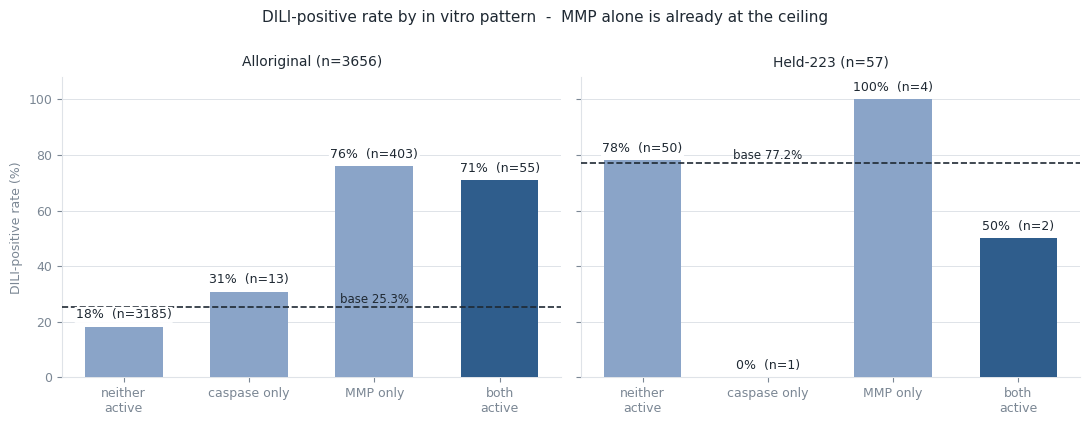

In [9]:
# The counts histogram mixes prevalence with toxicity. This is the chart the
# discussion claim actually needs: DILI+ rate within each in vitro cell, against
# the population base rate.
LBL = {(0, 0): 'neither\nactive', (0, 1): 'MMP only', (1, 0): 'caspase only',
       (1, 1): 'both\nactive'}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)

for ax, (g, df, title) in zip(axes, [
        (r_allo, allo, f'Alloriginal (n={len(allo)})'),
        (r_held, held, f'Held-223 (n={len(held)})')]):
    g = g.reindex([(0, 0), (1, 0), (0, 1), (1, 1)])
    names = [LBL[i] for i in g.index]
    colors = [BAR_HI if i == (1, 1) else BAR for i in g.index]
    ax.bar(names, 100 * g.dili_rate.values, color=colors, width=0.62, zorder=3)
    base = 100 * df.dili.mean()
    ax.axhline(base, color=INK, ls='--', lw=1.2, zorder=4)
    # park the base-rate label over the bar furthest from the base line
    free = int(np.argmax(np.abs(100 * g.dili_rate.values - base)))
    ax.text(free, base + 1.5, f'base {base:.1f}%', ha='center', fontsize=8.5,
            color=INK)
    for x, (rate, n) in enumerate(zip(g.dili_rate.values, g.n.values)):
        ax.text(x, 100 * rate + 2, f'{100 * rate:.0f}%  (n={n})', ha='center',
                va='bottom', fontsize=9, color=INK, zorder=6,
                bbox=dict(boxstyle='round,pad=0.12', fc='white', ec='none'))
    ax.set_title(title, fontsize=10, color=INK, pad=8)
    ax.set_ylim(0, 108)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.grid(axis='y', color=GRID, lw=0.7, zorder=0)
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)
    for s in ('left', 'bottom'):
        ax.spines[s].set_color(GRID)

axes[0].set_ylabel('DILI-positive rate (%)', fontsize=9, color=MUTED)
fig.suptitle('DILI-positive rate by in vitro pattern  -  MMP alone is already '
             'at the ceiling', fontsize=11, color=INK, y=1.0)
fig.tight_layout()
fig.savefig(f'{RES}/dili_rate_by_pattern.png', dpi=200, bbox_inches='tight')
plt.show()

In [10]:
# Is the in vitro pattern associated with DILI at all? Fisher on each contrast,
# on the Alloriginal pool, the only set with the counts to support a test.
def fisher(df, mask, name):
    a = df[mask]
    b = df[~mask]
    tab = [[int(a.dili.sum()), int((1 - a.dili).sum())],
           [int(b.dili.sum()), int((1 - b.dili).sum())]]
    orr, p = stats.fisher_exact(tab, alternative='greater')
    print(f'{name:34s} n={len(a):5d}  DILI+={a.dili.mean():.3f}  '
          f'OR={orr:5.2f}  p={p:.3g}')

print(f'Alloriginal base DILI+ rate = {allo.dili.mean():.3f}\n')
fisher(allo, (allo.caspase == 1) & (allo.mmp == 1), 'caspase+MMP both active')
fisher(allo, allo.mmp == 1, 'MMP active (caspase ignored)')
fisher(allo, allo.caspase == 1, 'caspase active (MMP ignored)')
fisher(allo, (allo.caspase == 0) & (allo.mmp == 1), 'MMP active, caspase inactive')

# Does caspase add anything once MMP is active?
sub = allo[allo.mmp == 1]
tab = pd.crosstab(sub.caspase, sub.dili)
orr, p = stats.fisher_exact(tab.values)
print(f'\nwithin MMP-active (n={len(sub)}): caspase vs DILI  '
      f'OR={orr:.2f}  two-sided p={p:.3g}')
print(tab)

Alloriginal base DILI+ rate = 0.253

caspase+MMP both active            n=   55  DILI+=0.709  OR= 7.48  p=1.04e-12
MMP active (caspase ignored)       n=  458  DILI+=0.753  OR=13.81  p=1.55e-131
caspase active (MMP ignored)       n=   68  DILI+=0.632  OR= 5.28  p=2.85e-11
MMP active, caspase inactive       n=  403  DILI+=0.759  OR=13.45  p=4.25e-116

within MMP-active (n=458): caspase vs DILI  OR=0.77  two-sided p=0.409
dili      0    1
caspase         
0        97  306
1        16   39


## Step 6 - the other direction

A rule is only useful if it also covers the positives. Of the DILI-positive
compounds, what fraction actually carries `1-1-1`.

In [11]:
for label, df in [('all three-way', tri), ('Alloriginal', allo),
                  ('Held-223', held)]:
    pos = df[df.dili == 1]
    n111 = int(((pos.caspase == 1) & (pos.mmp == 1)).sum())
    n_mmp = int((pos.mmp == 1).sum())
    print(f'{label:14s} DILI+ = {len(pos):5d}   '
          f'caspase+MMP both active: {n111:4d} ({n111 / len(pos):6.1%})   '
          f'MMP active: {n_mmp:4d} ({n_mmp / len(pos):6.1%})')

all three-way  DILI+ =  1056   caspase+MMP both active:   40 (  3.8%)   MMP active:  360 ( 34.1%)
Alloriginal    DILI+ =   924   caspase+MMP both active:   39 (  4.2%)   MMP active:  345 ( 37.3%)
Held-223       DILI+ =    44   caspase+MMP both active:    1 (  2.3%)   MMP active:    5 ( 11.4%)


## Step 7 - all 1,096 gold clinical compounds, measured where possible

Steps 1-6 are limited to compounds carrying a measured assay result, and only
**197** gold-standard clinical DILI drugs have both. The other 899 were never run
in these assays - the Tox21 10K library is mostly environmental and research
chemicals, while the gold DILI set is approved pharmaceuticals.

This step closes the gap the way reviewer comment 2 asks for: the consensus assay
models supply the in vitro axis where no measurement exists. The step is only
legitimate if those models are accurate, so that is established first, on the
compounds where the truth is known.

In [12]:
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve

gold = pd.read_csv(f'{LINK}/results/invitro_features.csv')
gold = gold[gold.dili_set.isin(['NCV-888', 'Held-223'])].copy()
gold = gold.rename(columns={'TOXICITY': 'dili'})
print(f'gold clinical DILI compounds: {len(gold)}  '
      f'DILI+ = {gold.dili.sum()} ({gold.dili.mean():.1%})\n')

# validation: do the OOB consensus models reproduce the measured labels?
truth = {'mmp': mmp, 'caspase': caspase}
thresh, rows = {}, []
for a in ('mmp', 'caspase'):
    m = gold.merge(truth[a], on='InChIKey')
    auc = roc_auc_score(m[a], m[f'{a}_prob'])
    ap = average_precision_score(m[a], m[f'{a}_prob'])
    fpr, tpr, cuts = roc_curve(m[a], m[f'{a}_prob'])
    thresh[a] = float(cuts[np.argmax(tpr - fpr)])          # Youden J
    rows.append(dict(assay=a, n_measured=len(m), actives=int(m[a].sum()),
                     roc_auc=round(auc, 3), pr_auc=round(ap, 3),
                     threshold=round(thresh[a], 3)))
val = pd.DataFrame(rows)
print('Consensus assay models vs measured labels, gold compounds only:')
print(val.to_string(index=False))
val.to_csv(f'{RES}/assay_model_validation.csv', index=False)

gold clinical DILI compounds: 1096  DILI+ = 708 (64.6%)

Consensus assay models vs measured labels, gold compounds only:
  assay  n_measured  actives  roc_auc  pr_auc  threshold
    mmp         230       25    0.959   0.744      0.549
caspase         307       21    0.936   0.623      0.268


In [13]:
# measured where available, model-predicted otherwise
for a in ('mmp', 'caspase'):
    gold = gold.merge(truth[a].rename(columns={a: f'{a}_meas'}),
                      on='InChIKey', how='left')
    gold[a] = np.where(gold[f'{a}_meas'].notna(), gold[f'{a}_meas'],
                       (gold[f'{a}_prob'] >= thresh[a]).astype(int)).astype(int)
    gold[f'{a}_src'] = np.where(gold[f'{a}_meas'].notna(), 'measured',
                                'predicted')
    n_m = int((gold[f'{a}_src'] == 'measured').sum())
    print(f'{a:8s}: {n_m} measured + {len(gold) - n_m} predicted '
          f'= {len(gold)}   (active: {int(gold[a].sum())})')

mmp     : 230 measured + 866 predicted = 1096   (active: 181)
caspase : 307 measured + 789 predicted = 1096   (active: 258)


                  count  % of gold
DILI-caspase-MMP                  
0-0-0               282      25.73
0-0-1                13       1.19
0-1-0                66       6.02
0-1-1                27       2.46
1-0-0               467      42.61
1-0-1                76       6.93
1-1-0               100       9.12
1-1-1                65       5.93


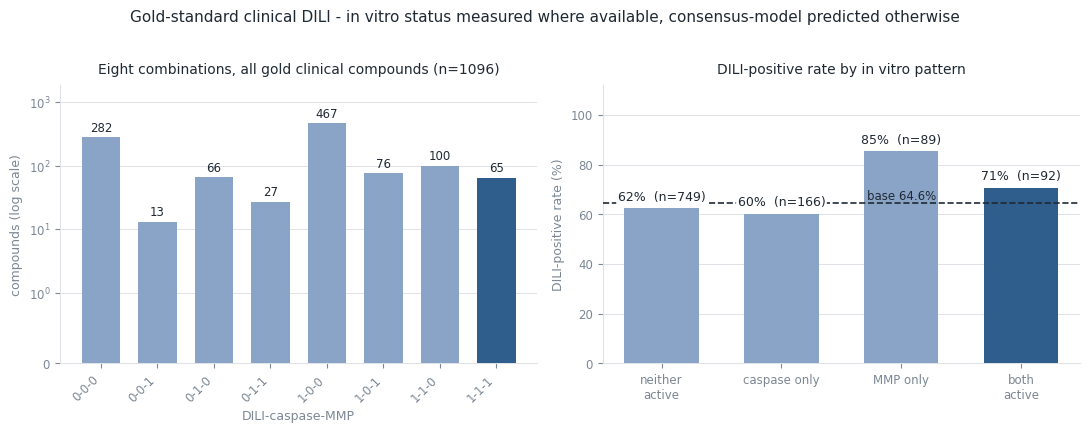


MMP-active vs rest (gold, hybrid):  OR=2.16  p=1.85e-05


In [14]:
pat_gold = patterns(gold)
pat_gold['% of gold'] = (100 * pat_gold['count'] / len(gold)).round(2)
print(pat_gold)
pat_gold.to_csv(f'{RES}/gold_pattern_counts.csv')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

c = pat_gold['count']
colors = [BAR_HI if i == '1-1-1' else BAR for i in c.index]
ax1.bar(c.index, c.values, color=colors, width=0.68, zorder=3)
for x, v in enumerate(c.values):
    ax1.text(x, v * 1.12 if v else 1.12, f'{v:,}', ha='center', va='bottom',
             fontsize=8.5, color=INK)
ax1.set_yscale('symlog', linthresh=1)
ax1.set_ylim(0, c.max() * 4)
ax1.set_title(f'Eight combinations, all gold clinical compounds (n={len(gold)})',
              fontsize=10, color=INK, pad=8)
ax1.set_xlabel('DILI-caspase-MMP', fontsize=9, color=MUTED)
ax1.set_ylabel('compounds (log scale)', fontsize=9, color=MUTED)
ax1.set_xticks(range(8))
ax1.set_xticklabels(c.index, rotation=45, ha='right')

g = gold.groupby(['caspase', 'mmp']).agg(n=('dili', 'size'),
                                         pos=('dili', 'sum'))
g['rate'] = g.pos / g.n
g = g.reindex([(0, 0), (1, 0), (0, 1), (1, 1)]).fillna(0)
base = 100 * gold.dili.mean()
colors = [BAR_HI if i == (1, 1) else BAR for i in g.index]
ax2.bar([LBL[i] for i in g.index], 100 * g.rate.values, color=colors,
        width=0.62, zorder=3)
ax2.axhline(base, color=INK, ls='--', lw=1.2, zorder=4)
ax2.text(int(np.argmax(np.abs(100 * g.rate.values - base))), base + 1.5,
         f'base {base:.1f}%',
         ha='center', fontsize=8.5, color=INK)
for x, (r, n) in enumerate(zip(g.rate.values, g.n.values)):
    ax2.text(x, 100 * r + 2, f'{100 * r:.0f}%  (n={int(n)})', ha='center',
             va='bottom', fontsize=9, color=INK, zorder=6,
             bbox=dict(boxstyle='round,pad=0.12', fc='white', ec='none'))
ax2.set_ylim(0, 112)
ax2.set_title('DILI-positive rate by in vitro pattern', fontsize=10,
              color=INK, pad=8)
ax2.set_ylabel('DILI-positive rate (%)', fontsize=9, color=MUTED)

for ax in (ax1, ax2):
    ax.tick_params(colors=MUTED, labelsize=8.5)
    ax.grid(axis='y', color=GRID, lw=0.7, zorder=0)
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)
    for s in ('left', 'bottom'):
        ax.spines[s].set_color(GRID)

fig.suptitle('Gold-standard clinical DILI - in vitro status measured where '
             'available, consensus-model predicted otherwise',
             fontsize=11, color=INK, y=1.02)
fig.tight_layout()
fig.savefig(f'{RES}/gold_three_way.png', dpi=200, bbox_inches='tight')
plt.show()

orr, p = stats.fisher_exact(
    [[int(gold[gold.mmp == 1].dili.sum()),
      int((1 - gold[gold.mmp == 1].dili).sum())],
     [int(gold[gold.mmp == 0].dili.sum()),
      int((1 - gold[gold.mmp == 0].dili).sum())]], alternative='greater')
print(f'\nMMP-active vs rest (gold, hybrid):  OR={orr:.2f}  p={p:.3g}')

## Step 8 - a true histogram, on the continuous scores

Everything above is a bar chart of category counts. A histogram needs a continuous
variable, and there is one: the consensus assay models output a probability per
compound rather than a yes/no. Binning those probabilities shows the whole
distribution instead of collapsing it at a threshold, and splitting each
distribution by clinical DILI status shows directly whether hepatotoxic drugs sit
at higher assay activity.

mmp     : median DILI+ 0.205 vs DILI- 0.144   Mann-Whitney p=3.74e-07
caspase : median DILI+ 0.125 vs DILI- 0.134   Mann-Whitney p=0.52


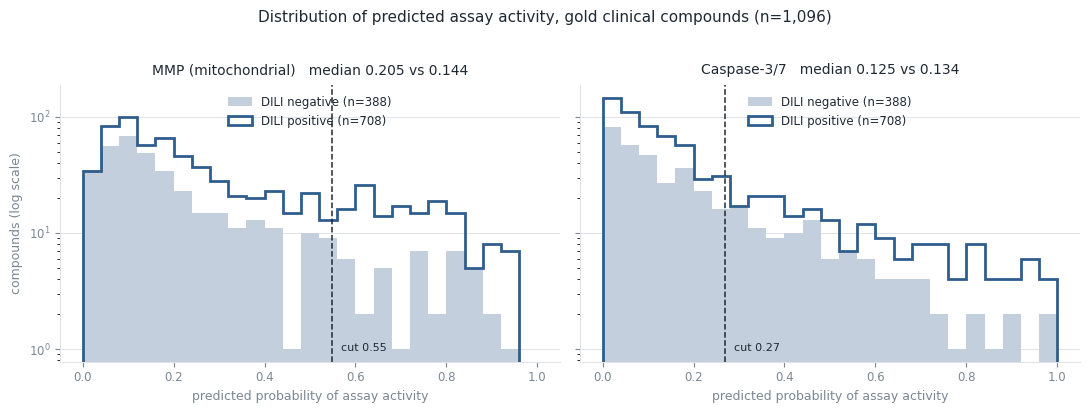

In [15]:
POS, NEG = '#2f5d8c', '#c3cfdd'
bins = np.linspace(0, 1, 26)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.0), sharey=True)
for ax, a, name in [(axes[0], 'mmp', 'MMP (mitochondrial)'),
                    (axes[1], 'caspase', 'Caspase-3/7')]:
    p = gold[gold.dili == 1][f'{a}_prob']
    n = gold[gold.dili == 0][f'{a}_prob']
    ax.hist(n, bins=bins, color=NEG, label=f'DILI negative (n={len(n)})',
            zorder=3)
    ax.hist(p, bins=bins, color=POS, histtype='step', lw=2,
            label=f'DILI positive (n={len(p)})', zorder=4)
    ax.axvline(thresh[a], color=INK, ls='--', lw=1.1, zorder=5)
    ax.text(thresh[a] + 0.02, 0.04, f'cut {thresh[a]:.2f}', fontsize=8,
            color=INK, transform=ax.get_xaxis_transform())
    ax.set_title(f'{name}   median {p.median():.3f} vs {n.median():.3f}',
                 fontsize=10, color=INK, pad=8)
    ax.set_xlabel('predicted probability of assay activity', fontsize=9,
                  color=MUTED)
    ax.set_yscale('log')
    ax.tick_params(colors=MUTED, labelsize=8.5)
    ax.grid(axis='y', color=GRID, lw=0.7, zorder=0)
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)
    for s in ('left', 'bottom'):
        ax.spines[s].set_color(GRID)
    leg = ax.legend(frameon=False, fontsize=8.5, loc='upper center')
    for t in leg.get_texts():
        t.set_color(INK)
    u, pu = stats.mannwhitneyu(p, n, alternative='greater')
    print(f'{a:8s}: median DILI+ {p.median():.3f} vs DILI- {n.median():.3f}   '
          f'Mann-Whitney p={pu:.3g}')

axes[0].set_ylabel('compounds (log scale)', fontsize=9, color=MUTED)
fig.suptitle('Distribution of predicted assay activity, gold clinical '
             'compounds (n=1,096)', fontsize=11, color=INK, y=1.02)
fig.tight_layout()
fig.savefig(f'{RES}/prob_histogram.png', dpi=200, bbox_inches='tight')
plt.show()

## What the numbers say

**1. The data reproduces, to within one compound.** 4,878 tested in both assays
against the paper's 4,879, and 105 dual-active against the paper's 106. The
one-compound gap comes from a label that ties on the InChIKey majority vote and is
dropped here; it is not a different dataset.

**2. Held-223 cannot answer this question.** Only 57 of the 222 held-out compounds
carry all three measured labels, and exactly **one** of them is `1-1-1`. Every
Held-223 cell is single-digit. The answer has to come from the Alloriginal pool
(3,656 compounds with all three labels), with Held-223 reported as coverage only.

**3. All-ones is enriched for DILI - strongly.** On Alloriginal, against a base
rate of 25.3%, compounds active in both assays are **70.9%** DILI-positive
(n=55, OR 7.48, p=1.0e-12). So the premise holds: if all three are 1, the compound
is usually hepatotoxic.

**4. But MMP is doing all of the work.** MMP-active alone gives **75.3%**
(n=458, OR 13.81), and MMP-active *with caspase inactive* gives **75.9%** - both
higher than the all-ones cell. Within the MMP-active compounds, caspase status is
unrelated to DILI (OR 0.77, two-sided p=0.41). Caspase alone, with MMP inactive,
gives 30.8% against the 25.3% base - barely moved. The three-way pattern is not
adding a third axis of information; it is an MMP result with a caspase column
attached.

**5. The rule has almost no reach.** Only **4.2%** of DILI-positive compounds are
`1-1-1` (39 of 924). MMP-active covers 37.3%. As a prediction rule, all-ones is
high-precision and near-zero-recall - it describes a small corner of the toxic
compounds rather than identifying them.

**Where this leaves the discussion.** The honest claim is "mitochondrial membrane
potential disruption is a strong positive indicator of DILI, and caspase-3/7
activation adds nothing beyond it", not "all three active implies toxic". The
latter is true but is a weaker restatement of the former. Worth noting this is
consistent with the paper's own pathway argument: caspase activation is largely a
*downstream consequence* of MMP disruption (105 of 125 caspase-actives are also
MMP-active), so it carries little independent signal.

Outputs: `results/pattern_counts.csv`, `results/dili_rate_by_cell.csv`,
`results/pattern_histogram.png`.